In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df_bugzilla = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bugzilla_fix.csv')
print(df_bugzilla.shape)
print(df_bugzilla.columns.tolist())
print(df_bugzilla.head())

Mounted at /content/drive
(32428, 5)
['Unnamed: 0.1', 'Unnamed: 0', 'Description', 'Fixing_time', 'Label']
   Unnamed: 0.1  Unnamed: 0  \
0             0           0   
1             1           1   
2             2           2   
3             3           3   
4             4           4   

                                         Description  Fixing_time  Label  
0   Created by Darrell Kindred  dkindred mozilla ...         5797      1  
1   Created by Darrell Kindred  dkindred mozilla ...          993      1  
2   Created by    msuencks marcant de  on Tuesday...          992      1  
3   Created by Darrell Kindred  dkindred mozilla ...          250      1  
4   Created by Darrell Kindred  dkindred mozilla ...          272      1  


In [5]:
import pandas as pd
from sklearn.utils import resample

# Load
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bugzilla_fix.csv')

# Label check
print(df['Label'].value_counts())
print(df['Label'].unique())

Label
0    24797
1     7631
Name: count, dtype: int64
[1 0]


In [6]:
import pandas as pd
from sklearn.utils import resample

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bugzilla_fix.csv')

# Fixing_time stats பாருங்க
print(df['Fixing_time'].describe())

count    32428.000000
mean       184.307389
std        647.333205
min          0.000000
25%          1.000000
50%         18.000000
75%         91.000000
max       8174.000000
Name: Fixing_time, dtype: float64


In [7]:
import pandas as pd
from sklearn.utils import resample

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Bugzilla_fix.csv')

# Text column
df['text'] = df['Description'].fillna('')

# Fixing_time based severity labeling
def assign_severity(fixing_time):
    if fixing_time > 91:
        return 'Critical'
    elif fixing_time >= 18:
        return 'High'
    else:
        return 'Low'

df['severity'] = df['Fixing_time'].apply(assign_severity)

print("Before balance:")
print(df['severity'].value_counts())

# Balance
total = len(df)
n_samples = total // 3
print(f"\nTotal: {total}, Each class: {n_samples}")

df_critical = df[df['severity'] == 'Critical']
df_high = df[df['severity'] == 'High']
df_low = df[df['severity'] == 'Low']

df_critical_bal = resample(df_critical, replace=True,
                           n_samples=n_samples, random_state=42)
df_high_bal = resample(df_high, replace=True,
                       n_samples=n_samples, random_state=42)
df_low_bal = resample(df_low, replace=False,
                      n_samples=n_samples, random_state=42)

df_balanced = pd.concat([df_critical_bal, df_high_bal, df_low_bal])
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print("\nAfter balance:")
print(df_balanced['severity'].value_counts())
print(f"Total: {len(df_balanced)}")

# Save
df_balanced.to_csv('/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_balanced.csv', index=False)
print("\nSaved!")

Before balance:
severity
Low         16095
High         8243
Critical     8090
Name: count, dtype: int64

Total: 32428, Each class: 10809

After balance:
severity
Low         10809
High        10809
Critical    10809
Name: count, dtype: int64
Total: 32427

Saved!


In [8]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

# Load balanced dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_balanced.csv')
print(df.shape)
print(df.columns.tolist())
print(df['severity'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(32427, 7)
['Unnamed: 0.1', 'Unnamed: 0', 'Description', 'Fixing_time', 'Label', 'text', 'severity']
severity
Low         10809
High        10809
Critical    10809
Name: count, dtype: int64


In [9]:
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# CLEAN TEXT
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_text)

# TRAIN TEST SPLIT
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["severity"]
)

X_train_text = train_df["clean_text"]
X_test_text = test_df["clean_text"]

y_train = train_df["severity"]
y_test = test_df["severity"]

# TF-IDF
bugzilla_vectorizer = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X_train = bugzilla_vectorizer.fit_transform(X_train_text)
X_test = bugzilla_vectorizer.transform(X_test_text)

print(X_train.shape)
print(X_test.shape)

joblib.dump(
    bugzilla_vectorizer,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_tfidf_vectorizer.pkl"
)

print("Bugzilla Severity TF-IDF Saved")

(25941, 10000)
(6486, 10000)
Bugzilla Severity TF-IDF Saved


Logistic Regression

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

# TRAIN MODEL
bugzilla_lr_model = LogisticRegression(
    max_iter=1000
)

bugzilla_lr_model.fit(
    X_train,
    y_train
)

print("Bugzilla Severity Logistic Regression Model Trained")

# PREDICT
y_pred = bugzilla_lr_model.predict(
    X_test
)

# ACCURACY
bugzilla_lr_acc = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", bugzilla_lr_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred
))

# SAVE MODEL
joblib.dump(
    bugzilla_lr_model,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_logistic_regression_model.pkl"
)

print("Bugzilla Severity Logistic Regression Model Saved")

Bugzilla Severity Logistic Regression Model Trained
Accuracy: 0.6975023126734505

Classification Report:

              precision    recall  f1-score   support

    Critical       0.78      0.77      0.77      2162
        High       0.63      0.62      0.62      2162
         Low       0.68      0.71      0.70      2162

    accuracy                           0.70      6486
   macro avg       0.70      0.70      0.70      6486
weighted avg       0.70      0.70      0.70      6486

Bugzilla Severity Logistic Regression Model Saved


Random Forest

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib

# TRAIN MODEL
bugzilla_rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

bugzilla_rf_model.fit(
    X_train,
    y_train
)

print("Bugzilla Severity Random Forest Model Trained")

# PREDICT
y_pred = bugzilla_rf_model.predict(
    X_test
)

# ACCURACY
bugzilla_rf_acc = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", bugzilla_rf_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred
))

# SAVE MODEL
joblib.dump(
    bugzilla_rf_model,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_random_forest_model.pkl"
)

print("Bugzilla Severity Random Forest Model Saved")

Bugzilla Severity Random Forest Model Trained
Accuracy: 0.831945729263028

Classification Report:

              precision    recall  f1-score   support

    Critical       0.87      0.90      0.89      2162
        High       0.86      0.74      0.80      2162
         Low       0.77      0.85      0.81      2162

    accuracy                           0.83      6486
   macro avg       0.83      0.83      0.83      6486
weighted avg       0.83      0.83      0.83      6486

Bugzilla Severity Random Forest Model Saved


SVM

In [12]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
import joblib

# TRAIN MODEL
bugzilla_svm_model = LinearSVC()

bugzilla_svm_model.fit(
    X_train,
    y_train
)

print("Bugzilla Severity SVM Model Trained")

# PREDICT
y_pred = bugzilla_svm_model.predict(
    X_test
)

# ACCURACY
bugzilla_svm_acc = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", bugzilla_svm_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred
))

# SAVE MODEL
joblib.dump(
    bugzilla_svm_model,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_svm_model.pkl"
)

print("Bugzilla Severity SVM Model Saved")

Bugzilla Severity SVM Model Trained
Accuracy: 0.7237126117792168

Classification Report:

              precision    recall  f1-score   support

    Critical       0.80      0.83      0.81      2162
        High       0.67      0.66      0.66      2162
         Low       0.70      0.68      0.69      2162

    accuracy                           0.72      6486
   macro avg       0.72      0.72      0.72      6486
weighted avg       0.72      0.72      0.72      6486

Bugzilla Severity SVM Model Saved


Naive Bayes

In [13]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
import joblib

# TRAIN MODEL
bugzilla_nb_model = MultinomialNB()

bugzilla_nb_model.fit(
    X_train,
    y_train
)

print("Bugzilla Severity Naive Bayes Model Trained")

# PREDICT
y_pred = bugzilla_nb_model.predict(
    X_test
)

# ACCURACY
bugzilla_nb_acc = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", bugzilla_nb_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred
))

# SAVE MODEL
joblib.dump(
    bugzilla_nb_model,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_naive_bayes_model.pkl"
)

print("Bugzilla Severity Naive Bayes Model Saved")

Bugzilla Severity Naive Bayes Model Trained
Accuracy: 0.5955905026210299

Classification Report:

              precision    recall  f1-score   support

    Critical       0.65      0.70      0.67      2162
        High       0.52      0.54      0.53      2162
         Low       0.63      0.55      0.59      2162

    accuracy                           0.60      6486
   macro avg       0.60      0.60      0.59      6486
weighted avg       0.60      0.60      0.59      6486

Bugzilla Severity Naive Bayes Model Saved


XGBoost

In [14]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import joblib

# LABEL ENCODING
severity_encoder = LabelEncoder()

y_train_encoded = severity_encoder.fit_transform(y_train)

y_test_encoded = severity_encoder.transform(y_test)

# TRAIN MODEL
bugzilla_xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    objective='multi:softmax',
    num_class=3,
    random_state=42
)

bugzilla_xgb_model.fit(
    X_train,
    y_train_encoded
)

print("Bugzilla Severity XGBoost Model Trained")

# PREDICT
y_pred_encoded = bugzilla_xgb_model.predict(
    X_test
)

# DECODE LABELS
y_pred = severity_encoder.inverse_transform(
    y_pred_encoded
)

# ACCURACY
bugzilla_xgb_acc = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", bugzilla_xgb_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred
))

# SAVE MODEL
joblib.dump(
    bugzilla_xgb_model,
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_xgboost_model.pkl"
)

print("Bugzilla Severity XGBoost Model Saved")

Bugzilla Severity XGBoost Model Trained
Accuracy: 0.7326549491211841

Classification Report:

              precision    recall  f1-score   support

    Critical       0.85      0.80      0.83      2162
        High       0.67      0.64      0.65      2162
         Low       0.69      0.76      0.72      2162

    accuracy                           0.73      6486
   macro avg       0.74      0.73      0.73      6486
weighted avg       0.74      0.73      0.73      6486

Bugzilla Severity XGBoost Model Saved


LSTM

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

import numpy as np
import pickle

# TOKENIZATION
tokenizer = Tokenizer(num_words=10000)

tokenizer.fit_on_texts(
    train_df["clean_text"]
)

X_train_seq = tokenizer.texts_to_sequences(
    train_df["clean_text"]
)

X_test_seq = tokenizer.texts_to_sequences(
    test_df["clean_text"]
)

# PAD SEQUENCES
max_len = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len
)

# LABEL ENCODING
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train
)

y_test_encoded = label_encoder.transform(
    y_test
)

# BUILD MODEL
bugzilla_lstm_model = Sequential()

bugzilla_lstm_model.add(
    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=max_len
    )
)

bugzilla_lstm_model.add(
    LSTM(128)
)

bugzilla_lstm_model.add(
    Dropout(0.5)
)

bugzilla_lstm_model.add(
    Dense(64, activation='relu')
)

bugzilla_lstm_model.add(
    Dense(3, activation='softmax')
)

# COMPILE
bugzilla_lstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# TRAIN
bugzilla_lstm_model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# EVALUATE
loss, accuracy = bugzilla_lstm_model.evaluate(
    X_test_pad,
    y_test_encoded
)

print("Bugzilla Severity LSTM Accuracy:", accuracy)

# PREDICT
y_pred_probs = bugzilla_lstm_model.predict(
    X_test_pad
)

y_pred = np.argmax(
    y_pred_probs,
    axis=1
)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE MODEL
bugzilla_lstm_model.save(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_lstm_model.keras"
)

# SAVE TOKENIZER
with open(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_tokenizer.pkl",
    "wb"
) as f:

    pickle.dump(tokenizer, f)

print("Bugzilla Severity LSTM Model Saved")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 147s 197ms/step - accuracy: 0.5510 - loss: 0.9218 - val_accuracy: 0.6139 - val_loss: 0.8239
Epoch 2/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 146s 200ms/step - accuracy: 0.6742 - loss: 0.7441 - val_accuracy: 0.6424 - val_loss: 0.8032
Epoch 3/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 143s 196ms/step - accuracy: 0.7439 - loss: 0.6137 - val_accuracy: 0.6601 - val_loss: 0.7849
Epoch 4/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 143s 196ms/step - accuracy: 0.7993 - loss: 0.5019 - val_accuracy: 0.6863 - val_loss: 0.8179
Epoch 5/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 149s 204ms/step - accuracy: 0.8421 - loss: 0.4121 - val_accuracy: 0.6994 - val_loss: 0.8546
203/203 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.7021 - loss: 0.8322
Bugzilla Severity LSTM Accuracy: 0.7021276354789734
203/203 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step

Classification Report:

              precision    recall  f1-score   support

    Critical       0.83      0.78      0.80      2162
        High       0.70      0.53      

BiLSTM

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional
from tensorflow.keras.layers import LSTM, Dense, Dropout

from sklearn.metrics import classification_report

import numpy as np

# BUILD MODEL
bugzilla_bilstm_model = Sequential()

bugzilla_bilstm_model.add(
    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=max_len
    )
)

bugzilla_bilstm_model.add(
    Bidirectional(
        LSTM(128)
    )
)

bugzilla_bilstm_model.add(
    Dropout(0.5)
)

bugzilla_bilstm_model.add(
    Dense(64, activation='relu')
)

bugzilla_bilstm_model.add(
    Dense(3, activation='softmax')
)

# COMPILE
bugzilla_bilstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# TRAIN
bugzilla_bilstm_model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# EVALUATE
loss, accuracy = bugzilla_bilstm_model.evaluate(
    X_test_pad,
    y_test_encoded
)

print("Bugzilla Severity BiLSTM Accuracy:", accuracy)

# PREDICT
y_pred_probs = bugzilla_bilstm_model.predict(
    X_test_pad
)

y_pred = np.argmax(
    y_pred_probs,
    axis=1
)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE MODEL
bugzilla_bilstm_model.save(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_bilstm_model.keras"
)

print("Bugzilla Severity BiLSTM Model Saved")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 275s 364ms/step - accuracy: 0.5655 - loss: 0.8928 - val_accuracy: 0.6143 - val_loss: 0.8119
Epoch 2/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 321s 362ms/step - accuracy: 0.6985 - loss: 0.6879 - val_accuracy: 0.6474 - val_loss: 0.7645
Epoch 3/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 268s 368ms/step - accuracy: 0.7971 - loss: 0.5034 - val_accuracy: 0.6867 - val_loss: 0.7612
Epoch 4/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 317s 361ms/step - accuracy: 0.8683 - loss: 0.3516 - val_accuracy: 0.7017 - val_loss: 0.8638
Epoch 5/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 320s 358ms/step - accuracy: 0.9080 - loss: 0.2538 - val_accuracy: 0.7229 - val_loss: 0.9150
203/203 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step - accuracy: 0.7334 - loss: 0.9148
Bugzilla Severity BiLSTM Accuracy: 0.7334258556365967
203/203 ━━━━━━━━━━━━━━━━━━━━ 22s 106ms/step

Classification Report:

              precision    recall  f1-score   support

    Critical       0.79      0.83      0.81      2162
        High       0.70      0.68   

CNN + BiLSTM

In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense, Dropout

from sklearn.metrics import classification_report

import numpy as np

# BUILD MODEL
bugzilla_cnn_bilstm_model = Sequential()

bugzilla_cnn_bilstm_model.add(
    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=max_len
    )
)

bugzilla_cnn_bilstm_model.add(
    Conv1D(
        filters=128,
        kernel_size=5,
        activation='relu'
    )
)

bugzilla_cnn_bilstm_model.add(
    MaxPooling1D(pool_size=2)
)

bugzilla_cnn_bilstm_model.add(
    Bidirectional(
        LSTM(128)
    )
)

bugzilla_cnn_bilstm_model.add(
    Dropout(0.5)
)

bugzilla_cnn_bilstm_model.add(
    Dense(64, activation='relu')
)

bugzilla_cnn_bilstm_model.add(
    Dense(3, activation='softmax')
)

# COMPILE
bugzilla_cnn_bilstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# TRAIN
bugzilla_cnn_bilstm_model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# EVALUATE
loss, accuracy = bugzilla_cnn_bilstm_model.evaluate(
    X_test_pad,
    y_test_encoded
)

print("Bugzilla Severity CNN + BiLSTM Accuracy:", accuracy)

# PREDICT
y_pred_probs = bugzilla_cnn_bilstm_model.predict(
    X_test_pad
)

y_pred = np.argmax(
    y_pred_probs,
    axis=1
)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE MODEL
bugzilla_cnn_bilstm_model.save(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_cnn_bilstm_model.keras"
)

print("Bugzilla Severity CNN + BiLSTM Model Saved")

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


730/730 ━━━━━━━━━━━━━━━━━━━━ 175s 230ms/step - accuracy: 0.5674 - loss: 0.8855 - val_accuracy: 0.6312 - val_loss: 0.7920
Epoch 2/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 169s 232ms/step - accuracy: 0.7173 - loss: 0.6549 - val_accuracy: 0.6717 - val_loss: 0.7451
Epoch 3/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 166s 227ms/step - accuracy: 0.8295 - loss: 0.4294 - val_accuracy: 0.7064 - val_loss: 0.7724
Epoch 4/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 167s 228ms/step - accuracy: 0.9102 - loss: 0.2458 - val_accuracy: 0.7414 - val_loss: 0.8071
Epoch 5/5
730/730 ━━━━━━━━━━━━━━━━━━━━ 166s 227ms/step - accuracy: 0.9524 - loss: 0.1417 - val_accuracy: 0.7441 - val_loss: 1.0402
203/203 ━━━━━━━━━━━━━━━━━━━━ 13s 62ms/step - accuracy: 0.7498 - loss: 1.0050
Bugzilla Severity CNN + BiLSTM Accuracy: 0.7497687339782715
203/203 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step

Classification Report:

              precision    recall  f1-score   support

    Critical       0.81      0.85      0.83      2162
        High       0.70      0.72      0.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import re

from sklearn.model_selection import train_test_split

# LOAD DATASET
df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_balanced.csv"
)

print(df.shape)

print(df["severity"].value_counts())

# CLEAN FUNCTION
def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+", "", text)

    text = re.sub(r"<.*?>", "", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

# CREATE CLEAN TEXT
df["clean_text"] = df["text"].apply(clean_text)

# TRAIN TEST SPLIT
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["severity"]
)

# LABELS
y_train = train_df["severity"]

y_test = test_df["severity"]

print(train_df.shape)
print(test_df.shape)

Mounted at /content/drive
(32427, 7)
severity
Low         10809
High        10809
Critical    10809
Name: count, dtype: int64
(25941, 8)
(6486, 8)


In [3]:
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import TrainingArguments, Trainer

import torch
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# LABEL ENCODING
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# TOKENIZER
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

train_encodings = bert_tokenizer(
    train_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = bert_tokenizer(
    test_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

class SeverityDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(self.labels[idx])

        return item

    def __len__(self):
        return len(self.labels)

train_dataset = SeverityDataset(train_encodings, y_train_encoded)
test_dataset = SeverityDataset(test_encodings, y_test_encoded)

# MODEL
bugzilla_bert_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

training_args = TrainingArguments(
    output_dir="./bugzilla_bert_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    save_strategy="no"
)

bugzilla_bert_trainer = Trainer(
    model=bugzilla_bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# TRAIN
bugzilla_bert_trainer.train()

# ACCURACY
predictions = bugzilla_bert_trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)

bugzilla_bert_acc = accuracy_score(y_test_encoded, y_pred)

print("Bugzilla Severity BERT Accuracy:", bugzilla_bert_acc)

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE
bugzilla_bert_model.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_bert_model"
)

bert_tokenizer.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_bert_model"
)

print("Bugzilla Severity BERT Model Saved")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (2 outputs left out)

Step,Training Loss
500,1.059510
1000,0.965157
1500,0.929220
2000,0.861028
2500,0.804769
3000,0.774552
3500,0.703938
4000,0.604361
4500,0.601575


Bugzilla Severity BERT Accuracy: 0.6652790625963614
              precision    recall  f1-score   support

    Critical       0.71      0.80      0.75      2162
        High       0.60      0.62      0.61      2162
         Low       0.68      0.57      0.62      2162

    accuracy                           0.67      6486
   macro avg       0.66      0.67      0.66      6486
weighted avg       0.66      0.67      0.66      6486



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Bugzilla Severity BERT Model Saved


RoBERTa

In [4]:
from transformers import RobertaTokenizer, RobertaForSequenceClassification
from transformers import TrainingArguments, Trainer

import torch
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# LABEL ENCODING
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train
)

y_test_encoded = label_encoder.transform(
    y_test
)

# TOKENIZER
roberta_tokenizer = RobertaTokenizer.from_pretrained(
    "roberta-base"
)

# TOKENIZATION
train_encodings = roberta_tokenizer(
    train_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = roberta_tokenizer(
    test_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# DATASET CLASS
class SeverityDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx]
        )

        return item

    def __len__(self):
        return len(self.labels)

# DATASETS
train_dataset = SeverityDataset(
    train_encodings,
    y_train_encoded
)

test_dataset = SeverityDataset(
    test_encodings,
    y_test_encoded
)

# MODEL
bugzilla_roberta_model = RobertaForSequenceClassification.from_pretrained(
    "roberta-base",
    num_labels=3
)

# TRAINING ARGUMENTS
training_args = TrainingArguments(
    output_dir="./bugzilla_roberta_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    save_strategy="no",
    logging_steps=500
)

# TRAINER
bugzilla_roberta_trainer = Trainer(
    model=bugzilla_roberta_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# TRAIN
bugzilla_roberta_trainer.train()

# PREDICT
predictions = bugzilla_roberta_trainer.predict(
    test_dataset
)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

# ACCURACY
roberta_acc = accuracy_score(
    y_test_encoded,
    y_pred
)

print("Bugzilla Severity RoBERTa Accuracy:", roberta_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE MODEL
bugzilla_roberta_model.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_roberta_model"
)

roberta_tokenizer.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_roberta_model"
)

print("Bugzilla Severity RoBERTa Model Saved")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

... (2 outputs left out)

Step,Training Loss
500,1.039967
1000,0.961840
1500,0.929487
2000,0.877036
2500,0.841711
3000,0.818427
3500,0.768402
4000,0.718630
4500,0.711594


Bugzilla Severity RoBERTa Accuracy: 0.6302806043786617

Classification Report:

              precision    recall  f1-score   support

    Critical       0.73      0.70      0.71      2162
        High       0.55      0.58      0.56      2162
         Low       0.63      0.61      0.62      2162

    accuracy                           0.63      6486
   macro avg       0.63      0.63      0.63      6486
weighted avg       0.63      0.63      0.63      6486



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Bugzilla Severity RoBERTa Model Saved


CodeBERT

In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer

import torch
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# LABEL ENCODING
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(
    y_train
)

y_test_encoded = label_encoder.transform(
    y_test
)

# TOKENIZER
codebert_tokenizer = AutoTokenizer.from_pretrained(
    "microsoft/codebert-base"
)

# TOKENIZATION
train_encodings = codebert_tokenizer(
    train_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = codebert_tokenizer(
    test_df["clean_text"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

# DATASET CLASS
class SeverityDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx]
        )

        return item

    def __len__(self):
        return len(self.labels)

# DATASETS
train_dataset = SeverityDataset(
    train_encodings,
    y_train_encoded
)

test_dataset = SeverityDataset(
    test_encodings,
    y_test_encoded
)

# MODEL
bugzilla_codebert_model = AutoModelForSequenceClassification.from_pretrained(
    "microsoft/codebert-base",
    num_labels=3
)

# TRAINING ARGUMENTS
training_args = TrainingArguments(
    output_dir="./bugzilla_codebert_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    save_strategy="no"
)

# TRAINER
bugzilla_codebert_trainer = Trainer(
    model=bugzilla_codebert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# TRAIN
bugzilla_codebert_trainer.train()

# PREDICT
predictions = bugzilla_codebert_trainer.predict(
    test_dataset
)

y_pred = np.argmax(
    predictions.predictions,
    axis=1
)

# ACCURACY
codebert_acc = accuracy_score(
    y_test_encoded,
    y_pred
)

print("Bugzilla Severity CodeBERT Accuracy:", codebert_acc)

# REPORT
print("\nClassification Report:\n")

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

# SAVE MODEL
bugzilla_codebert_model.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_codebert_model"
)

codebert_tokenizer.save_pretrained(
    "/content/drive/MyDrive/Colab Notebooks/bugzilla_severity_codebert_model"
)

print("Bugzilla Severity CodeBERT Model Saved")

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

... (4 outputs left out)

Step,Training Loss
500,1.027543
1000,0.942441
1500,0.914446
2000,0.851936
2500,0.792898
3000,0.774311
3500,0.720262
4000,0.651526
4500,0.642561


Bugzilla Severity CodeBERT Accuracy: 0.6490903484427999

Classification Report:

              precision    recall  f1-score   support

    Critical       0.72      0.77      0.74      2162
        High       0.59      0.59      0.59      2162
         Low       0.64      0.59      0.61      2162

    accuracy                           0.65      6486
   macro avg       0.65      0.65      0.65      6486
weighted avg       0.65      0.65      0.65      6486



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Bugzilla Severity CodeBERT Model Saved


                  Model  Accuracy
1         Random Forest    0.8319
6          CNN + BiLSTM    0.7500
7               XGBoost    0.7327
5                BiLSTM    0.7300
2                   SVM    0.7237
4                  LSTM    0.7000
0   Logistic Regression    0.6975
8                  BERT    0.6653
10             CodeBERT    0.6491
9               RoBERTa    0.6303
3           Naive Bayes    0.5956


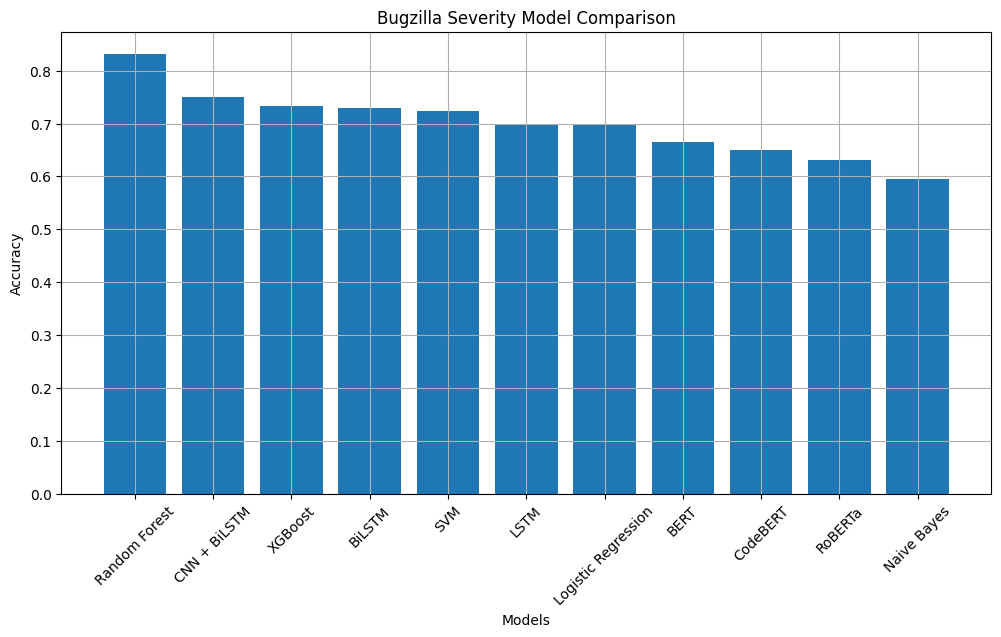

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# =========================
# MODEL NAMES
# =========================

models = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "Naive Bayes",
    "LSTM",
    "BiLSTM",
    "CNN + BiLSTM",
    "XGBoost",
    "BERT",
    "RoBERTa",
    "CodeBERT"
]

# =========================
# BUGZILLA ACCURACY
# =========================

bugzilla_acc = [
    0.6975,
    0.8319,
    0.7237,
    0.5956,
    0.7000,
    0.7300,
    0.7500,
    0.7327,
    0.6653,
    0.6303,
    0.6491
]

# =========================
# DATAFRAME
# =========================

bugzilla_df = pd.DataFrame({
    "Model": models,
    "Accuracy": bugzilla_acc
})

# SORT
bugzilla_df = bugzilla_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(bugzilla_df)

# SAVE CSV
bugzilla_df.to_csv(
    "bugzilla_model_comparison.csv",
    index=False
)

# =========================
# BAR CHART
# =========================

plt.figure(figsize=(12,6))

plt.bar(
    bugzilla_df["Model"],
    bugzilla_df["Accuracy"]
)

plt.xticks(rotation=45)

plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.title("Bugzilla Severity Model Comparison")

plt.grid(True)

# SAVE GRAPH
plt.savefig(
    "bugzilla_model_comparison.png"
)

plt.show()

# =========================
# DOWNLOAD
# =========================

files.download(
    "bugzilla_model_comparison.csv"
)

files.download(
    "bugzilla_model_comparison.png"
)